# Potential Outcomes, DAGs, and Good vs Bad Controls

**What you'll learn**

- Reason fluently in potential outcomes: why unit-level effects are fundamentally unobservable, and what ATE, ATT, and CATE each mean and when they differ.
- Decompose the naive treated-vs-untreated comparison into *(causal effect) + (selection bias)* — numerically, in a simulated world where both potential outcomes are visible.
- Verify in simulation exactly why randomization works: balance on observables *and unobservables*, and unbiasedness of the difference-in-means.
- Read DAGs like a senior scientist: confounder / mediator / collider structures, d-separation intuition, and the backdoor criterion.
- The topic that separates seniors from mid-levels: the **bias arithmetic of good vs bad controls** — confounders (must control), mediators (don't), colliders (never), M-bias (looks safe, isn't), and precision covariates (a free lunch).
- A compact decision framework for "should this covariate go into the model?"

**Why it matters in interviews**

- "We can't run an experiment here — how would you estimate the effect?" is *the* defining senior DS/AS question. Potential-outcomes language is table stakes for answering it.
- "Which covariates would you adjust for, and why?" is a favorite probe. "Control for everything we log" is an instant red flag; the DAG-based answer is what interviewers want to hear.
- Colliders and post-treatment conditioning are classic gotcha questions ("you only analyzed users who completed onboarding — what's wrong?").
- Every observational method later in this module — propensity scores ([02_propensity_ipw_doubly_robust.ipynb](02_propensity_ipw_doubly_robust.ipynb)), DiD ([03_did_synthetic_control.ipynb](03_did_synthetic_control.ipynb)), IV ([04_iv_rdd.ipynb](04_iv_rdd.ipynb)) — presumes you can choose a valid adjustment set. That skill is built here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import statsmodels.formula.api as smf

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "figure.dpi": 100,
})

PALETTE = {
    "treatment": "#7fb3d8",   # blue
    "outcome": "#8fce8f",     # green
    "control": "#f2b06e",     # orange = candidate control under discussion
    "neutral": "#e0e0e0",     # gray
    "unobserved": "#f7f7f7",  # dashed border = unobserved
}


def draw_dag(edges, pos, roles=None, title="", ax=None, edge_labels=None):
    """Draw a small DAG with role-based colors (dashed border = unobserved)."""
    roles = roles or {}
    G = nx.DiGraph(edges)
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 3))
    solid = [n for n in G.nodes() if roles.get(n) != "unobserved"]
    dashed = [n for n in G.nodes() if roles.get(n) == "unobserved"]
    nx.draw_networkx_nodes(
        G, pos, nodelist=solid, node_size=1500, ax=ax, edgecolors="black",
        node_color=[PALETTE[roles.get(n, "neutral")] for n in solid])
    if dashed:
        coll = nx.draw_networkx_nodes(
            G, pos, nodelist=dashed, node_size=1500, ax=ax,
            edgecolors="gray", node_color=PALETTE["unobserved"])
        coll.set_linestyle("dashed")
    nx.draw_networkx_labels(G, pos, font_size=11, ax=ax)
    nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowsize=16,
                           width=1.5, node_size=1500)
    if edge_labels:
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels,
                                     font_size=9, ax=ax)
    ax.set_title(title)
    ax.set_axis_off()
    ax.margins(0.18)

## 1. Potential outcomes, sharp and fast

Each unit $i$ carries two **potential outcomes**: $Y_i(1)$ (outcome if treated) and
$Y_i(0)$ (outcome if not). The unit-level effect is $\tau_i = Y_i(1) - Y_i(0)$. We only
ever observe $Y_i = T_i\,Y_i(1) + (1-T_i)\,Y_i(0)$ — one of the two. That is the
**fundamental problem of causal inference**: unit-level effects are unobservable, so all of
causal inference is about estimating *averages* of $\tau_i$ over some population:

- **ATE** $= E[Y(1) - Y(0)]$ — average effect over everyone.
- **ATT** $= E[Y(1) - Y(0) \mid T=1]$ — average effect over those actually treated.
- **CATE** $= E[Y(1) - Y(0) \mid X=x]$ — average effect within a covariate stratum (see [05_uplift_cate.ipynb](05_uplift_cate.ipynb) for estimating these).

Keep *estimand* (the target, e.g. ATE), *estimator* (the recipe, e.g. difference-in-means),
and *estimate* (the number you got) distinct — interviewers listen for this.

The naive comparison decomposes exactly (an algebraic identity, not an approximation):

$$\underbrace{E[Y \mid T=1] - E[Y \mid T=0]}_{\text{naive diff-in-means}}
  = \underbrace{E[Y(1) - Y(0) \mid T=1]}_{\text{ATT}}
  + \underbrace{E[Y(0) \mid T=1] - E[Y(0) \mid T=0]}_{\text{selection bias}}$$

Selection bias asks: *would the treated group have differed from the control group even
without treatment?* Under self-selection the answer is usually yes.

**Simulated world.** A subscription business offers an opt-in "premium onboarding call"
($T$) hoping to lift 90-day spend ($Y$). Because we are the simulator, we get to see both
potential outcomes for every customer — the god-view no analyst ever has.
By construction the population ATE is **25** (dollars), effects are larger for more engaged
customers, and highly engaged customers are far more likely to opt in.

In [2]:
n_pop = 20_000

engagement = rng.normal(50, 15, n_pop)                       # activity score
tenure = 6 + 0.4 * engagement + rng.normal(0, 8, n_pop)      # months, correlated w/ engagement

Y0 = 120 + 5 * engagement + 2 * tenure + rng.normal(0, 40, n_pop)   # spend if NOT treated
tau_i = 25 + 0.6 * (engagement - 50)                                # heterogeneous unit effect
Y1 = Y0 + tau_i                                                     # spend if treated

# Self-selection: highly engaged customers opt in far more often
p_optin = 1 / (1 + np.exp(-(engagement - 60) / 8))
T_self = (rng.random(n_pop) < p_optin).astype(int)
Y_obs = np.where(T_self == 1, Y1, Y0)

pop = pd.DataFrame({
    "engagement": engagement, "tenure": tenure,
    "Y0": Y0, "Y1": Y1, "tau_i": tau_i, "T": T_self, "Y_obs": Y_obs,
})
print(f"share treated (self-selected): {T_self.mean():.3f}\n")
print("God-view of the first 5 customers (no analyst ever sees both Y0 and Y1):")
print(pop[["engagement", "Y0", "Y1", "tau_i", "T", "Y_obs"]].head().round(1).to_string())

share treated (self-selected): 0.311

God-view of the first 5 customers (no analyst ever sees both Y0 and Y1):
   engagement     Y0     Y1  tau_i  T  Y_obs
0        54.6  386.0  413.7   27.7  0  386.0
1        34.4  295.5  311.1   15.6  0  295.5
2        61.3  499.7  531.4   31.8  0  499.7
3        64.1  500.4  533.8   33.5  0  500.4
4        20.7  159.3  166.7    7.4  0  159.3


### The selection-bias decomposition, numerically

We now compute every term of the identity. Watch two things: (1) the naive difference is
wildly larger than any causal quantity, and (2) ATT > ATE because the customers who opt in
are exactly those with the largest individual effects (effect heterogeneity + selective
uptake is *the* mechanism that makes ATT and ATE diverge).

In [3]:
ate = pop["tau_i"].mean()
att = pop.loc[pop["T"] == 1, "tau_i"].mean()
naive = pop.loc[pop["T"] == 1, "Y_obs"].mean() - pop.loc[pop["T"] == 0, "Y_obs"].mean()
sel_bias = pop.loc[pop["T"] == 1, "Y0"].mean() - pop.loc[pop["T"] == 0, "Y0"].mean()

print(f"sample ATE   E[Y1 - Y0]           = {ate:8.2f}")
print(f"sample ATT   E[Y1 - Y0 | T=1]     = {att:8.2f}")
print(f"naive diff   E[Y|T=1] - E[Y|T=0]  = {naive:8.2f}")
print(f"selection bias E[Y0|T=1]-E[Y0|T=0]= {sel_bias:8.2f}")
print(f"\nATT + selection bias              = {att + sel_bias:8.2f}")
print(f"identity error |naive - (ATT+bias)| = {abs(naive - (att + sel_bias)):.2e}")
print(f"\nnaive / ATE inflation factor: {naive / ate:.1f}x")

sample ATE   E[Y1 - Y0]           =    25.05
sample ATT   E[Y1 - Y0 | T=1]     =    32.66
naive diff   E[Y|T=1] - E[Y|T=0]  =   139.26
selection bias E[Y0|T=1]-E[Y0|T=0]=   106.60

ATT + selection bias              =   139.26
identity error |naive - (ATT+bias)| = 2.84e-14

naive / ATE inflation factor: 5.6x


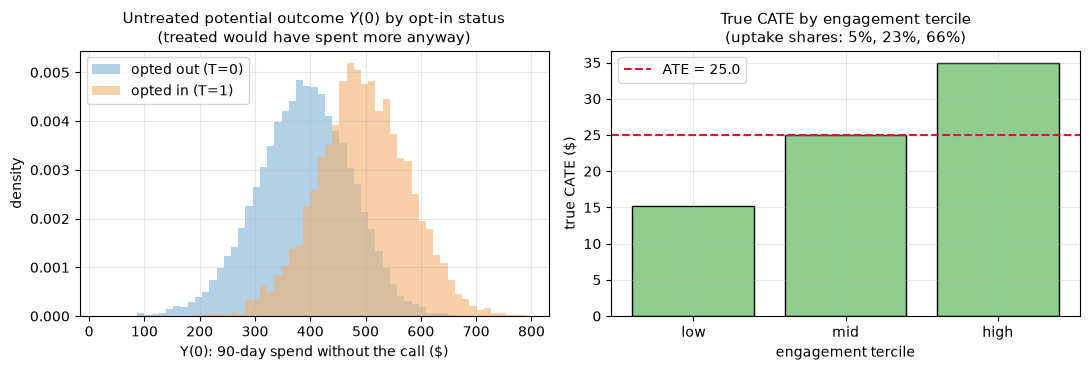

            true_CATE  share_treated
engagement                          
low             15.20           0.05
mid             25.02           0.23
high            34.92           0.66


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(pop["Y0"].min(), pop["Y0"].max(), 60)
for t, lab, c in [(0, "opted out (T=0)", "#7fb3d8"), (1, "opted in (T=1)", "#f2b06e")]:
    axes[0].hist(pop.loc[pop["T"] == t, "Y0"], bins=bins, alpha=0.6,
                 density=True, label=lab, color=c)
axes[0].set_title("Untreated potential outcome $Y(0)$ by opt-in status\n"
                  "(treated would have spent more anyway)")
axes[0].set_xlabel("Y(0): 90-day spend without the call ($)")
axes[0].set_ylabel("density")
axes[0].legend()

terc = pd.qcut(pop["engagement"], 3, labels=["low", "mid", "high"])
cate = pop.groupby(terc, observed=True).agg(
    true_CATE=("tau_i", "mean"), share_treated=("T", "mean"))
axes[1].bar(cate.index.astype(str), cate["true_CATE"], color="#8fce8f",
            edgecolor="black")
axes[1].axhline(ate, ls="--", color="crimson", label=f"ATE = {ate:.1f}")
axes[1].set_title("True CATE by engagement tercile\n(uptake shares: "
                  + ", ".join(f"{s:.0%}" for s in cate["share_treated"]) + ")")
axes[1].set_xlabel("engagement tercile")
axes[1].set_ylabel("true CATE ($)")
axes[1].legend()
fig.tight_layout()
plt.show()

print(cate.round(2).to_string())

The naive comparison is **more than five times** the true ATE, and even the true ATT sits far
below it — almost all of the observed gap is selection bias: engaged, long-tenured
customers both opt in more *and* spend more regardless. This is the same confounding logic
behind Simpson's paradox
([../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb)).

## 2. Randomization: the great equalizer

Randomize $T$ and you force $(Y(0), Y(1)) \perp T$: assignment carries no information about
what would have happened either way. Two consequences, both checkable in our god-view world:

1. **Balance** — treated and control groups match in distribution on every covariate,
   *including unobservables* (in expectation). We verify balance on $Y(0)$ itself, a
   quantity no real analyst can even compute.
2. **Unbiasedness** — the selection-bias term is zero in expectation, so
   $E[\hat\Delta] = E[Y(1)] - E[Y(0)] = \text{ATE}$ (not just the ATT). We verify by
   replaying the random assignment 2,000 times.

A standard balance metric is the **standardized mean difference**
$\text{SMD} = (\bar x_1 - \bar x_0) / s_{\text{pooled}}$; $|\text{SMD}| < 0.1$ is the usual
"balanced" convention (it will reappear in propensity-score diagnostics,
[02_propensity_ipw_doubly_robust.ipynb](02_propensity_ipw_doubly_robust.ipynb)).

In [5]:
def smd(x, t):
    """Standardized mean difference of covariate x between t==1 and t==0."""
    x1, x0 = x[t == 1], x[t == 0]
    pooled = np.sqrt((x1.var(ddof=1) + x0.var(ddof=1)) / 2)
    return (x1.mean() - x0.mean()) / pooled


T_rand = rng.integers(0, 2, n_pop)  # coin-flip assignment on the SAME population

balance = pd.DataFrame({
    "SMD self-selected": [smd(pop[c].to_numpy(), T_self) for c in ["engagement", "tenure", "Y0"]],
    "SMD randomized": [smd(pop[c].to_numpy(), T_rand) for c in ["engagement", "tenure", "Y0"]],
}, index=["engagement", "tenure", "Y0  (unobservable!)"])
print(balance.round(3).to_string())

                     SMD self-selected  SMD randomized
engagement                       1.499           0.014
tenure                           0.789          -0.014
Y0  (unobservable!)              1.280           0.008


true sample ATE                      :   25.05
mean diff-in-means over 2000 randomizations:   25.04   (unbiased for ATE)
mean naive diff over 2000 self-selections  :  138.76   (= ATT + selection bias)


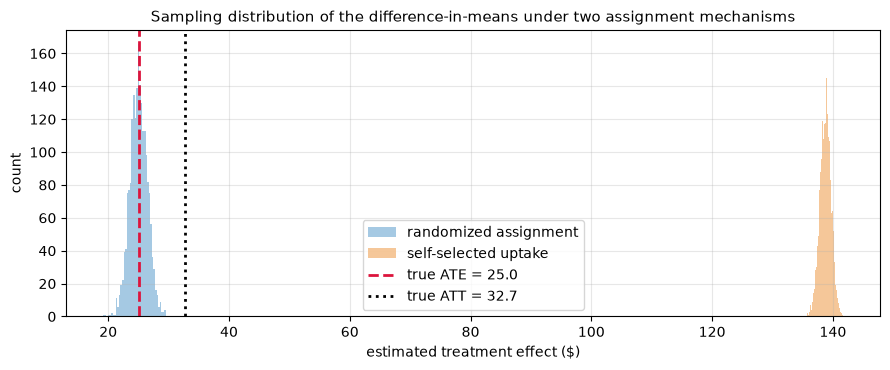

In [6]:
n_reps = 2000
est_rand = np.empty(n_reps)
est_self = np.empty(n_reps)
for i in range(n_reps):
    tr = rng.integers(0, 2, n_pop)                    # fresh randomization
    y = np.where(tr == 1, Y1, Y0)
    est_rand[i] = y[tr == 1].mean() - y[tr == 0].mean()

    ts = rng.random(n_pop) < p_optin                  # fresh self-selection
    y = np.where(ts, Y1, Y0)
    est_self[i] = y[ts].mean() - y[~ts].mean()

print(f"true sample ATE                      : {ate:7.2f}")
print(f"mean diff-in-means over {n_reps} randomizations: {est_rand.mean():7.2f}   (unbiased for ATE)")
print(f"mean naive diff over {n_reps} self-selections  : {est_self.mean():7.2f}   (= ATT + selection bias)")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(est_rand, bins=40, alpha=0.7, label="randomized assignment", color="#7fb3d8")
ax.hist(est_self, bins=40, alpha=0.7, label="self-selected uptake", color="#f2b06e")
ax.axvline(ate, color="crimson", ls="--", lw=2, label=f"true ATE = {ate:.1f}")
ax.axvline(att, color="black", ls=":", lw=2, label=f"true ATT = {att:.1f}")
ax.set_title("Sampling distribution of the difference-in-means under two assignment mechanisms")
ax.set_xlabel("estimated treatment effect ($)")
ax.set_ylabel("count")
ax.legend()
fig.tight_layout()
plt.show()

The randomized estimator's distribution is centered on the ATE; the self-selected one is
centered on ATT + selection bias — no amount of extra data fixes it, because the bias is in
the *assignment mechanism*, not the sample size. This is the formal sense in which
randomization is the gold standard: it delivers identification **by design**, with no
modeling assumptions. Everything in [../02_ab_testing/](../02_ab_testing/01_ab_test_end_to_end.ipynb)
builds on this guarantee.

When you *can't* randomize, you need assumptions about the assignment mechanism — and DAGs
are the language for stating them.

## 3. DAGs: three primitive structures and d-separation

A causal DAG encodes assumptions: an arrow $A \to B$ means "A may directly cause B"; a
*missing* arrow is the strong claim (no direct effect). Every DAG is built from three
primitives, and association "flows" through them by three rules:

| structure | name | marginal $X,Y$ | conditioned on middle node |
|---|---|---|---|
| $X \leftarrow Z \rightarrow Y$ | fork (confounder) | associated | independent |
| $X \rightarrow M \rightarrow Y$ | chain (mediator) | associated | independent |
| $X \rightarrow C \leftarrow Y$ | collider | **independent** | **associated** |

**d-separation in one breath:** a path transmits association unless it is *blocked*. Chains
and forks are open by default and blocked by conditioning on the middle node. Colliders are
blocked by default and **opened** by conditioning on the collider *or any of its
descendants*. $X$ and $Y$ are d-separated given $S$ iff every path between them is blocked
— and d-separation implies conditional independence in the data the model generates.
Conditioning is not a one-way "removes association" operation; on colliders it *creates*
association. That asymmetry is the source of every "bad control" below.

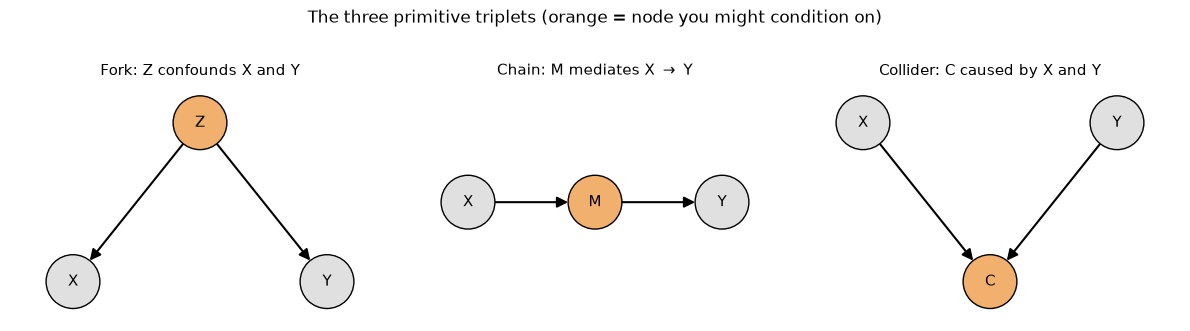

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
draw_dag([("Z", "X"), ("Z", "Y")], {"Z": (1, 1), "X": (0, 0), "Y": (2, 0)},
         roles={"Z": "control"}, title="Fork: Z confounds X and Y", ax=axes[0])
draw_dag([("X", "M"), ("M", "Y")], {"X": (0, 0), "M": (1, 0), "Y": (2, 0)},
         roles={"M": "control"}, title="Chain: M mediates X $\\to$ Y", ax=axes[1])
draw_dag([("X", "C"), ("Y", "C")], {"X": (0, 1), "Y": (2, 1), "C": (1, 0)},
         roles={"C": "control"}, title="Collider: C caused by X and Y", ax=axes[2])
fig.suptitle("The three primitive triplets (orange = node you might condition on)", y=1.02)
fig.tight_layout()
plt.show()

**Numerical check.** For each triplet we simulate 20,000 draws and compare the marginal
correlation of $X,Y$ with their partial correlation given the middle node (correlation of
residuals after regressing each on the conditioning variable — exact for linear Gaussian
systems). Watch the collider row flip from zero to strongly negative.

In [8]:
def partial_corr(df, x, y, given):
    rx = smf.ols(f"{x} ~ {given}", data=df).fit().resid
    ry = smf.ols(f"{y} ~ {given}", data=df).fit().resid
    return np.corrcoef(rx, ry)[0, 1]


n = 20_000
# fork
Z = rng.normal(0, 1, n)
fork = pd.DataFrame({"Z": Z, "X": 0.9 * Z + rng.normal(0, 1, n),
                     "Y": 0.9 * Z + rng.normal(0, 1, n)})
# chain
X = rng.normal(0, 1, n)
M = 0.9 * X + rng.normal(0, 1, n)
chain = pd.DataFrame({"X": X, "M": M, "Y": 0.9 * M + rng.normal(0, 1, n)})
# collider
X = rng.normal(0, 1, n)
Y = rng.normal(0, 1, n)
coll = pd.DataFrame({"X": X, "Y": Y, "C": 0.8 * X + 0.8 * Y + rng.normal(0, 1, n)})

dsep = pd.DataFrame([
    {"structure": "fork  X <- Z -> Y", "corr(X,Y)": fork["X"].corr(fork["Y"]),
     "corr(X,Y | mid)": partial_corr(fork, "X", "Y", "Z"),
     "conditioning on middle node": "blocks the path"},
    {"structure": "chain X -> M -> Y", "corr(X,Y)": chain["X"].corr(chain["Y"]),
     "corr(X,Y | mid)": partial_corr(chain, "X", "Y", "M"),
     "conditioning on middle node": "blocks the path"},
    {"structure": "collider X -> C <- Y", "corr(X,Y)": coll["X"].corr(coll["Y"]),
     "corr(X,Y | mid)": partial_corr(coll, "X", "Y", "C"),
     "conditioning on middle node": "OPENS the path"},
]).set_index("structure")
print(dsep.round(3).to_string())

                      corr(X,Y)  corr(X,Y | mid) conditioning on middle node
structure                                                                   
fork  X <- Z -> Y         0.450            0.006             blocks the path
chain X -> M -> Y         0.517            0.005             blocks the path
collider X -> C <- Y     -0.003           -0.390              OPENS the path


### The backdoor criterion

A set $S$ satisfies the **backdoor criterion** relative to $(T, Y)$ if:

1. no node in $S$ is a descendant of $T$, and
2. $S$ blocks every path from $T$ to $Y$ that enters $T$ through an arrow *into* $T$
   (every "backdoor path").

Then the causal effect is identified by adjustment:
$E[Y \mid do(T{=}t)] = E_S\big[\,E[Y \mid T{=}t, S]\,\big]$.

Condition 1 rules out mediators and treatment-caused colliders. Condition 2 is subtler than
"block all confounding": because conditioning can *open* collider paths, an adjustment set
can fail the criterion by including a variable that unblocks a backdoor path (that's M-bias,
scenario (d) below). "Pre-treatment" is therefore **not** a sufficient qualification for a
control variable.

## 4. Good vs bad controls: the bias arithmetic

This is the senior topic. For each case we use a small **linear structural model** (SEM),
so every bias has an exact closed form. Two tools make the arithmetic honest:

- `simulate_sem` draws data from the SEM;
- `implied_ols` computes the **exact population value** of any regression coefficient from
  the SEM's implied covariance matrix, $\Sigma = (I-B)^{-1} D (I-B)^{-\top}$ — no sampling
  noise, no asymptotics. Bias is a property of the *estimand you actually target*, and this
  separates it cleanly from estimation noise.

Throughout, the true causal effect of $T$ on $Y$ is $\tau = 2$, $n = 20{,}000$, and $T$ is
Gaussian to keep the algebra exact (every conclusion is identical with binary treatments —
scenario (e) uses one). Edge labels on each DAG show the structural coefficients. The
taxonomy follows Cinelli, Forney & Pearl, *"A Crash Course in Good and Bad Controls"* (2022).

In [9]:
TAU = 2.0
N = 20_000


def simulate_sem(sem, n, rng):
    """sem: list of (var, {parent: coef}, noise_sd) in topological order."""
    data = {}
    for var, parents, sd in sem:
        val = rng.normal(0, sd, n)
        for p, w in parents.items():
            val = val + w * data[p]
        data[var] = val
    return pd.DataFrame(data)


def implied_ols(sem, y, xs):
    """Exact population OLS coefficients of y ~ xs implied by the linear SEM."""
    order = [v for v, _, _ in sem]
    idx = {v: i for i, v in enumerate(order)}
    k = len(order)
    B, D = np.zeros((k, k)), np.zeros(k)
    for v, parents, sd in sem:
        D[idx[v]] = sd ** 2
        for p, w in parents.items():
            B[idx[v], idx[p]] = w
    A = np.linalg.inv(np.eye(k) - B)
    S = A @ np.diag(D) @ A.T
    xi = [idx[v] for v in xs]
    beta = np.linalg.solve(S[np.ix_(xi, xi)], S[xi, idx[y]])
    return dict(zip(xs, beta))


def sem_edges(sem):
    return {(p, v): w for v, parents, _ in sem for p, w in parents.items()}


def fit_models(df, specs):
    """OLS for each (label, formula); returns coef and SE on T."""
    rows = []
    for label, formula in specs:
        m = smf.ols(formula, data=df).fit()
        rows.append({"model": label, "coef_T": m.params["T"], "se_T": m.bse["T"]})
    return pd.DataFrame(rows).set_index("model")


def scenario_report(sem, specs, truth=TAU):
    """Fit each spec on fresh data; attach the exact population coefficient."""
    df = simulate_sem(sem, N, rng)
    res = fit_models(df, specs)
    pops = []
    for _, formula in specs:
        xs = [v.strip() for v in formula.split("~")[1].split("+")]
        pops.append(implied_ols(sem, "Y", xs)["T"])
    res["population_coef"] = pops
    res["truth"] = truth
    res["bias (population)"] = res["population_coef"] - truth
    return df, res


def plot_scenario(sem, pos, roles, res, dag_title, truth=TAU):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4),
                                   gridspec_kw={"width_ratios": [1, 1.25]})
    labels = {e: f"{w:g}" for e, w in sem_edges(sem).items()}
    draw_dag(list(labels), pos, roles=roles, title=dag_title, ax=ax1,
             edge_labels=labels)
    ypos = np.arange(len(res))[::-1]
    ax2.errorbar(res["coef_T"], ypos, xerr=1.96 * res["se_T"], fmt="o",
                 capsize=4, color="#33557a", label="OLS estimate (95% CI)")
    ax2.scatter(res["population_coef"], ypos, marker="x", s=70, color="#c0392b",
                zorder=3, label="exact population value")
    ax2.axvline(truth, ls="--", color="crimson", lw=1.5,
                label=f"true effect $\\tau$ = {truth:g}")
    ax2.set_yticks(ypos)
    ax2.set_yticklabels(res.index)
    ax2.set_xlabel("coefficient on T")
    ax2.set_title("Estimate vs truth")
    ax2.legend(loc="best", fontsize=8)
    fig.tight_layout()
    plt.show()


ledger = {}  # scenario -> results table, summarized at the end

### (a) Omitting a confounder biases — the classic

$Z \to T$ and $Z \to Y$: a backdoor path $T \leftarrow Z \rightarrow Y$ is open, so
`Y ~ T` mixes the causal effect with the confounded association. The **omitted-variable
bias formula** (see [../01_statistical_foundations/03_regression_the_workhorse.ipynb](../01_statistical_foundations/03_regression_the_workhorse.ipynb))
gives the exact amount:

$$\text{bias} = \gamma \cdot \frac{\text{Cov}(Z, T)}{\text{Var}(T)}
  = 1.5 \times \frac{0.8}{1.64} \approx 0.732
  \quad\Rightarrow\quad \text{plim of naive coefficient} \approx 2.732.$$

Controlling $Z$ closes the backdoor and recovers $\tau = 2$ exactly.

                  coef_T   se_T  population_coef  truth  bias (population)
model                                                                     
Y ~ T   (omit Z)   2.735  0.008            2.732    2.0              0.732
Y ~ T + Z          2.002  0.007            2.000    2.0              0.000

OVB formula: gamma * Cov(Z,T)/Var(T) = 1.5 * 0.8 / 1.64 = 0.7317
population naive coef = tau + OVB    = 2.7317


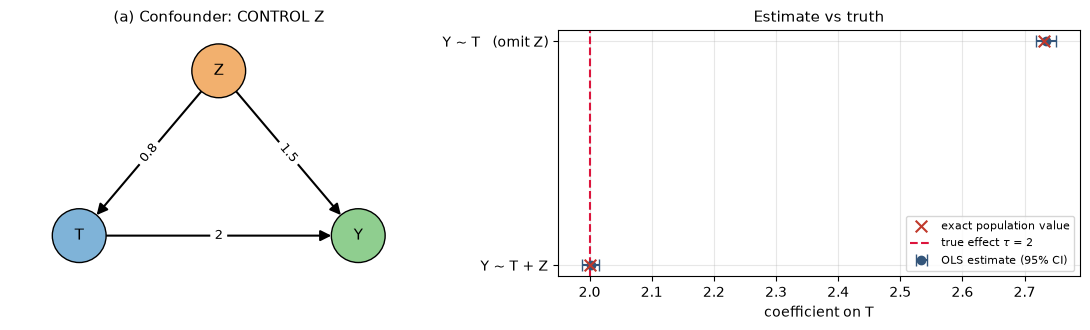

In [10]:
sem_a = [
    ("Z", {}, 1.0),
    ("T", {"Z": 0.8}, 1.0),
    ("Y", {"T": TAU, "Z": 1.5}, 1.0),
]
df_a, res_a = scenario_report(sem_a, [("Y ~ T   (omit Z)", "Y ~ T"),
                                      ("Y ~ T + Z", "Y ~ T + Z")])
print(res_a.round(3).to_string())
ovb = 1.5 * 0.8 / (0.8 ** 2 + 1.0)
print(f"\nOVB formula: gamma * Cov(Z,T)/Var(T) = 1.5 * 0.8 / 1.64 = {ovb:.4f}")
print(f"population naive coef = tau + OVB    = {TAU + ovb:.4f}")

plot_scenario(sem_a, {"Z": (1, 1), "T": (0, 0), "Y": (2, 0)},
              {"T": "treatment", "Y": "outcome", "Z": "control"},
              res_a, "(a) Confounder: CONTROL Z")
ledger["(a) confounder — control it"] = res_a

### (b) Controlling a mediator masks the effect

$T \to M \to Y$ plus a direct edge $T \to Y$. The **total effect** — what a decision-maker
almost always wants ("what happens to spend if we launch this?") — is
direct + indirect $= 0.8 + 0.8 \times 1.5 = 2.0$. Conditioning on $M$ blocks the indirect
path and `Y ~ T + M` returns only the **direct effect** 0.8. That is not a bug if mediation
analysis is your goal, but it is a different estimand requiring extra assumptions
(no unobserved $M$–$Y$ confounding, which is *not* granted by randomizing $T$). The classic
real-world version: "the experiment lifted revenue, but the effect disappears once we
control for sessions" — sessions are the mechanism, controlling them defines away the effect.

                          coef_T   se_T  population_coef  truth  bias (population)
model                                                                             
Y ~ T   (total effect)     2.012  0.013              2.0    2.0                0.0
Y ~ T + M  (direct only)   0.816  0.009              0.8    2.0               -1.2

total effect = direct + indirect = 0.8 + 0.8*1.5 = 2.0


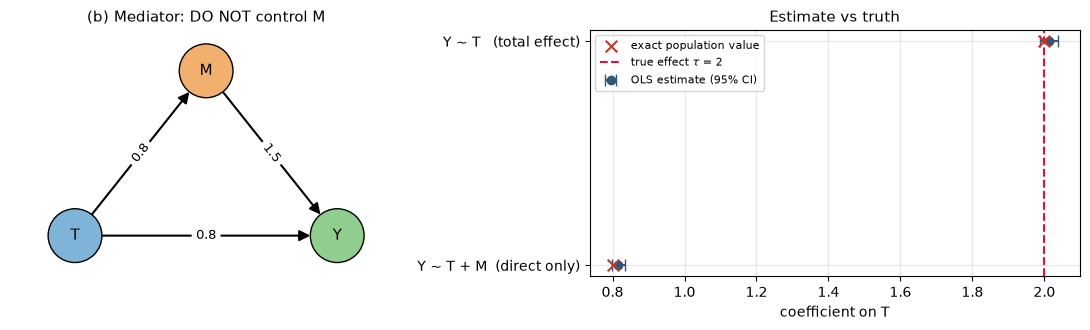

In [11]:
sem_b = [
    ("T", {}, 1.0),
    ("M", {"T": 0.8}, 1.0),
    ("Y", {"T": 0.8, "M": 1.5}, 1.0),
]
df_b, res_b = scenario_report(sem_b, [("Y ~ T   (total effect)", "Y ~ T"),
                                      ("Y ~ T + M  (direct only)", "Y ~ T + M")])
print(res_b.round(3).to_string())
print(f"\ntotal effect = direct + indirect = 0.8 + 0.8*1.5 = {0.8 + 0.8 * 1.5:.1f}")

plot_scenario(sem_b, {"T": (0, 0), "M": (1, 0.9), "Y": (2, 0)},
              {"T": "treatment", "Y": "outcome", "M": "control"},
              res_b, "(b) Mediator: DO NOT control M")
ledger["(b) mediator — don't control"] = res_b

### (c) Controlling a collider induces bias

$T \to C \leftarrow Y$: with no backdoor path, `Y ~ T` is already unbiased. $C$ is caused by
*both* treatment and outcome — think "customer filed a churn-save ticket", driven by having
received the treatment and by low spend. Conditioning on $C$ opens the path
$T \to C \leftarrow Y$ and drags the coefficient far from the truth: the exact population
value of the adjusted coefficient here is $\approx 1.013$ — half the true effect, from
adding one "harmless-looking" covariate.

                        coef_T   se_T  population_coef  truth  bias (population)
model                                                                           
Y ~ T   (correct)        2.007  0.007            2.000    2.0              0.000
Y ~ T + C  (collider!)   1.022  0.012            1.013    2.0             -0.987


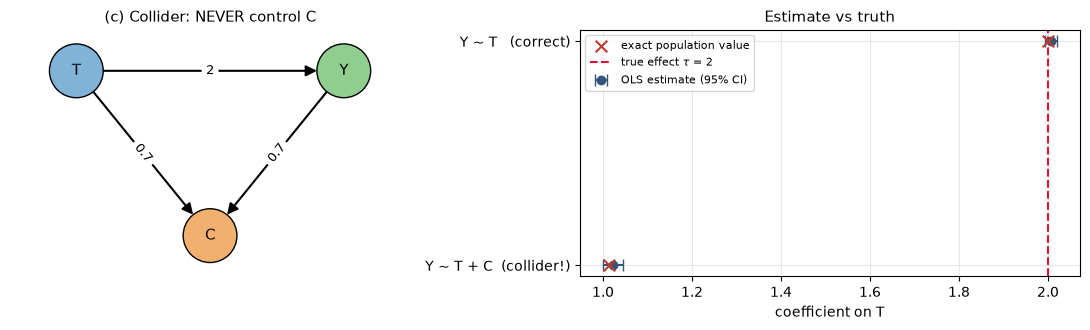

In [12]:
sem_c = [
    ("T", {}, 1.0),
    ("Y", {"T": TAU}, 1.0),
    ("C", {"T": 0.7, "Y": 0.7}, 1.0),
]
df_c, res_c = scenario_report(sem_c, [("Y ~ T   (correct)", "Y ~ T"),
                                      ("Y ~ T + C  (collider!)", "Y ~ T + C")])
print(res_c.round(3).to_string())

plot_scenario(sem_c, {"T": (0, 1), "Y": (2, 1), "C": (1, 0)},
              {"T": "treatment", "Y": "outcome", "C": "control"},
              res_c, "(c) Collider: NEVER control C")
ledger["(c) collider — never control"] = res_c

### (d) M-bias: the pre-treatment variable that betrays you

The trap for people whose rule is "controlling for pre-treatment variables is always safe."
Here $Z$ is measured *before* treatment and is correlated with both $T$ and $Y$ — it looks
exactly like a confounder in the data. But structurally $Z$ is a **collider** on the path
$T \leftarrow U_1 \rightarrow Z \leftarrow U_2 \rightarrow Y$ ($U_1, U_2$ unobserved).
Unadjusted, that path is blocked and `Y ~ T` is unbiased. Adjusting for $Z$ opens it:
the population value of the adjusted coefficient is $\approx 1.80$ — a 10% bias
manufactured out of nothing.

Business shape: $U_1$ = risk appetite (drives both a marketing opt-in $T$ and past survey
response $Z$), $U_2$ = wealth (drives $Z$ and spend $Y$). The survey response $Z$ is
pre-treatment, observed, correlated with everything — and poison to control.

                      coef_T   se_T  population_coef  truth  bias (population)
model                                                                         
Y ~ T   (correct)      1.994  0.007            2.000    2.0              0.000
Y ~ T + Z  (M-bias!)   1.790  0.007            1.801    2.0             -0.199

Z *looks* like a confounder: corr(Z,T) = 0.408, corr(Z,Y) = 0.550


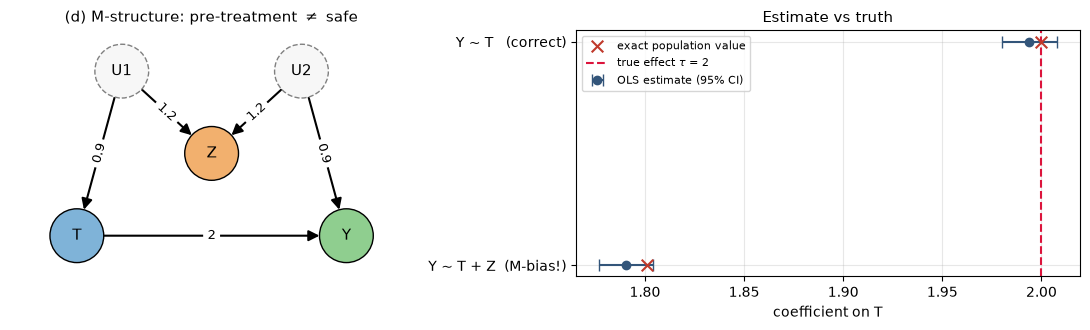

In [13]:
sem_d = [
    ("U1", {}, 1.0),
    ("U2", {}, 1.0),
    ("Z", {"U1": 1.2, "U2": 1.2}, 1.0),
    ("T", {"U1": 0.9}, 1.0),
    ("Y", {"T": TAU, "U2": 0.9}, 1.0),
]
df_d, res_d = scenario_report(sem_d, [("Y ~ T   (correct)", "Y ~ T"),
                                      ("Y ~ T + Z  (M-bias!)", "Y ~ T + Z")])
print(res_d.round(3).to_string())
print(f"\nZ *looks* like a confounder: corr(Z,T) = {df_d['Z'].corr(df_d['T']):.3f}, "
      f"corr(Z,Y) = {df_d['Z'].corr(df_d['Y']):.3f}")

plot_scenario(sem_d,
              {"T": (0, 0), "Y": (2.4, 0), "U1": (0.4, 1.4), "U2": (2.0, 1.4),
               "Z": (1.2, 0.7)},
              {"T": "treatment", "Y": "outcome", "Z": "control",
               "U1": "unobserved", "U2": "unobserved"},
              res_d, "(d) M-structure: pre-treatment $\\neq$ safe")
ledger["(d) M-bias — don't control"] = res_d

### (e) The good control you should always add: a pre-treatment predictor of Y

$T$ randomized (Bernoulli), $X \to Y$ only. There is no backdoor to close, so both
regressions are unbiased — but adjusting for $X$ soaks up outcome variance and shrinks the
standard error. With $\text{Var}(3X) = 9$ and residual variance $4$, the theoretical SE
ratio is $\sqrt{13/4} \approx 1.80$ — the adjusted estimator is worth roughly **3x the
sample size**, and 1,000 replications below reproduce the gain (empirical ratio ~1.7).
This is exactly the logic of regression adjustment and
CUPED in experiments — see [../02_ab_testing/03_variance_reduction_cuped.ipynb](../02_ab_testing/03_variance_reduction_cuped.ipynb).

           mean estimate  SD of estimates  truth
Y ~ T              2.008            0.157    2.0
Y ~ T + X          2.000            0.092    2.0

empirical SE ratio: 1.72   (theory: sqrt(13/4) = 1.80)
equivalent sample-size multiplier: 3.0x


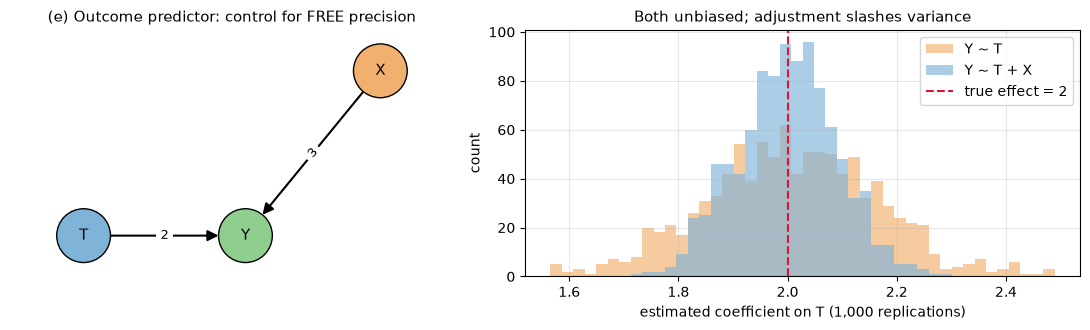

In [14]:
sem_e = [("X", {}, 1.0), ("T", {}, 1.0), ("Y", {"T": TAU, "X": 3.0}, 2.0)]

reps, n_e = 1000, 2000
est_e = np.empty((reps, 2))
for i in range(reps):
    X = rng.normal(0, 1, n_e)
    T = rng.integers(0, 2, n_e).astype(float)
    Y = TAU * T + 3.0 * X + rng.normal(0, 2.0, n_e)
    M1 = np.column_stack([np.ones(n_e), T])
    M2 = np.column_stack([np.ones(n_e), T, X])
    est_e[i, 0] = np.linalg.lstsq(M1, Y, rcond=None)[0][1]
    est_e[i, 1] = np.linalg.lstsq(M2, Y, rcond=None)[0][1]

summ_e = pd.DataFrame({
    "mean estimate": est_e.mean(axis=0),
    "SD of estimates": est_e.std(axis=0, ddof=1),
}, index=["Y ~ T", "Y ~ T + X"])
summ_e["truth"] = TAU
print(summ_e.round(3).to_string())
ratio = summ_e.loc["Y ~ T", "SD of estimates"] / summ_e.loc["Y ~ T + X", "SD of estimates"]
print(f"\nempirical SE ratio: {ratio:.2f}   (theory: sqrt(13/4) = {np.sqrt(13 / 4):.2f})")
print(f"equivalent sample-size multiplier: {ratio ** 2:.1f}x")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4),
                               gridspec_kw={"width_ratios": [1, 1.25]})
labels = {e: f"{w:g}" for e, w in sem_edges(sem_e).items()}
draw_dag(list(labels), {"T": (0, 0), "Y": (1.2, 0), "X": (2.2, 0.9)},
         roles={"T": "treatment", "Y": "outcome", "X": "control"},
         title="(e) Outcome predictor: control for FREE precision", ax=ax1,
         edge_labels=labels)
bins = np.linspace(est_e.min(), est_e.max(), 45)
ax2.hist(est_e[:, 0], bins=bins, alpha=0.65, label="Y ~ T", color="#f2b06e")
ax2.hist(est_e[:, 1], bins=bins, alpha=0.65, label="Y ~ T + X", color="#7fb3d8")
ax2.axvline(TAU, ls="--", color="crimson", label="true effect = 2")
ax2.set_title("Both unbiased; adjustment slashes variance")
ax2.set_xlabel("estimated coefficient on T (1,000 replications)")
ax2.set_ylabel("count")
ax2.legend()
fig.tight_layout()
plt.show()

res_e = pd.DataFrame({"coef_T": est_e.mean(axis=0),
                      "se_T": est_e.std(axis=0, ddof=1),
                      "population_coef": [TAU, TAU], "truth": TAU},
                     index=["Y ~ T", "Y ~ T + X"])
res_e["bias (population)"] = 0.0
ledger["(e) outcome predictor — control for precision"] = res_e

### Scorecard: all five cases in one table

(`coef_T` = point estimate on one simulated draw; `population_coef` = the exact value that
regression converges to; `bias (population)` = structural bias, immune to sampling noise.
For (e), `se_T` holds the replication SD — the row pair shows the precision gain.)

In [15]:
scorecard = pd.concat(ledger, names=["scenario", "model"]).round(3)
scorecard["verdict"] = np.where(scorecard["bias (population)"].abs() < 1e-9,
                                "unbiased", "BIASED")
print(scorecard.to_string())

                                                                        coef_T   se_T  population_coef  truth  bias (population)   verdict
scenario                                      model                                                                                       
(a) confounder — control it                   Y ~ T   (omit Z)           2.735  0.008            2.732    2.0              0.732    BIASED
                                              Y ~ T + Z                  2.002  0.007            2.000    2.0              0.000  unbiased
(b) mediator — don't control                  Y ~ T   (total effect)     2.012  0.013            2.000    2.0              0.000  unbiased
                                              Y ~ T + M  (direct only)   0.816  0.009            0.800    2.0             -1.200    BIASED
(c) collider — never control                  Y ~ T   (correct)          2.007  0.007            2.000    2.0              0.000  unbiased
                           

## 5. Decision framework: should this covariate go into the model?

Ask these questions **in order** about a candidate covariate $W$, using your causal graph
(draw it — literally — before touching the regression):

1. **Could $W$ be affected by the treatment?** (post-treatment: mediators, treatment-caused
   colliders, proxies of $Y$) → **Exclude.** If you truly want direct effects, that is
   mediation analysis — a different estimand with stronger assumptions.
2. **Does $W$ cause both $T$ and $Y$ (or proxy such a common cause)?** → **Confounder:
   include.** This is the only case where inclusion is *required* for identification.
3. **Does $W$ cause only $Y$?** → **Include for precision.** Unbiased either way; smaller
   standard errors with it (case (e), CUPED logic).
4. **Does $W$ cause only $T$?** → **Exclude.** It cannot close any backdoor, it inflates
   the variance of $\hat\tau$, and under residual unmeasured confounding it *amplifies*
   bias (demonstrated in Pitfalls below). Its proper use is as an instrument —
   [04_iv_rdd.ipynb](04_iv_rdd.ipynb).
5. **Is $W$ pre-treatment but plausibly a collider of unobserved causes (M-structure)?** →
   **Exclude**, or reason explicitly about magnitudes: if $W$ is *also* a genuine confounder
   ("butterfly" structure), neither choice is unbiased and you must argue which bias is
   smaller — say so out loud, with a sensitivity analysis.

| $W$'s role in the graph | Include? | If you get it wrong |
|---|---|---|
| Confounder ($W \to T$, $W \to Y$) | **Yes — required** | Omitted-variable bias (a) |
| Mediator ($T \to W \to Y$) | No (for total effects) | Effect masked (b) |
| Collider ($T \to W \leftarrow Y$) or descendant of $Y$ | **Never** | Bias created from nothing (c) |
| M-structure ($U_1 \to W \leftarrow U_2$) | No | Bias created from nothing (d) |
| Outcome-only predictor ($W \to Y$) | Yes — free precision | Wider CIs than necessary (e) |
| Treatment-only predictor ($W \to T$) | No | Variance up, bias amplified (Pitfall 2) |

The one-line summary interviewers love: **the adjustment set is chosen by the causal graph,
not by the correlation matrix, and not by what improves $R^2$ or predictive fit.**

## 6. Pitfalls: how good analysts pick bad controls

### Pitfall 1 — the kitchen-sink regression

"Throw in every covariate we log" combines all the failure modes at once. One dataset,
containing a confounder $Z$, a mediator $M$, and a collider $C$: watch the estimate
degrade as "controls" accumulate. Note the kitchen sink *looks* the most rigorous and its
$R^2$ is the highest — predictive fit is actively misleading about causal validity.

                                     coef_T   se_T  population_coef     R2
model                                                                     
Y ~ T            (omits confounder)   2.729  0.012            2.732  0.728
Y ~ T + Z        (CORRECT)            2.005  0.013            2.000  0.808
Y ~ T + Z + M    (adds mediator)      0.818  0.009            0.800  0.940
Y ~ T + Z + M + C  (kitchen sink)     0.222  0.010            0.208  0.960

true total effect of T on Y: 2.0


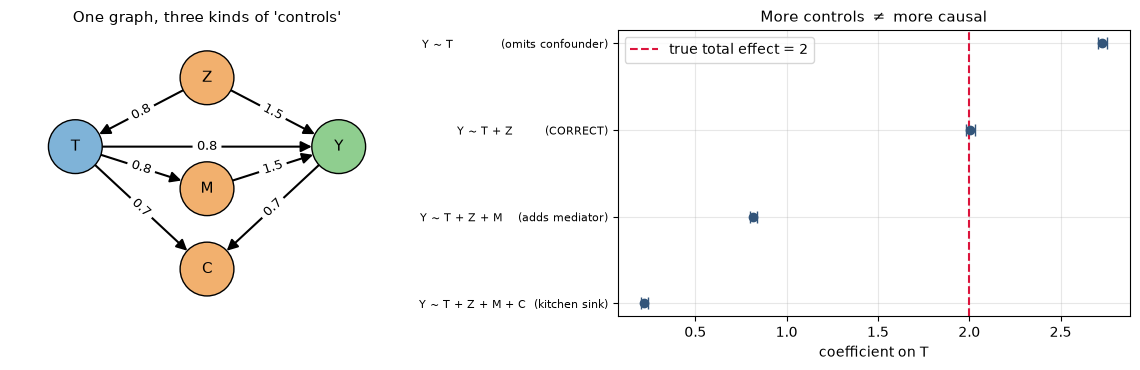

In [16]:
sem_ks = [
    ("Z", {}, 1.0),
    ("T", {"Z": 0.8}, 1.0),
    ("M", {"T": 0.8}, 1.0),
    ("Y", {"T": 0.8, "M": 1.5, "Z": 1.5}, 1.0),
    ("C", {"T": 0.7, "Y": 0.7}, 1.0),
]
# total effect of T on Y: 0.8 (direct) + 0.8*1.5 (via M) = 2.0
df_ks = simulate_sem(sem_ks, N, rng)
specs_ks = [("Y ~ T            (omits confounder)", "Y ~ T"),
            ("Y ~ T + Z        (CORRECT)", "Y ~ T + Z"),
            ("Y ~ T + Z + M    (adds mediator)", "Y ~ T + Z + M"),
            ("Y ~ T + Z + M + C  (kitchen sink)", "Y ~ T + Z + M + C")]
res_ks = fit_models(df_ks, specs_ks)
res_ks["population_coef"] = [
    implied_ols(sem_ks, "Y", [v.strip() for v in f.split("~")[1].split("+")])["T"]
    for _, f in specs_ks]
res_ks["R2"] = [smf.ols(f, data=df_ks).fit().rsquared for _, f in specs_ks]
print(res_ks.round(3).to_string())
print(f"\ntrue total effect of T on Y: {0.8 + 0.8 * 1.5:.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.8),
                               gridspec_kw={"width_ratios": [1, 1.3]})
labels = {e: f"{w:g}" for e, w in sem_edges(sem_ks).items()}
draw_dag(list(labels),
         {"Z": (1.2, 1.9), "T": (0, 1), "Y": (2.4, 1), "M": (1.2, 0.45),
          "C": (1.2, -0.6)},
         roles={"T": "treatment", "Y": "outcome", "Z": "control",
                "M": "control", "C": "control"},
         title="One graph, three kinds of 'controls'", ax=ax1, edge_labels=labels)
ypos = np.arange(len(res_ks))[::-1]
ax2.errorbar(res_ks["coef_T"], ypos, xerr=1.96 * res_ks["se_T"], fmt="o",
             capsize=4, color="#33557a")
ax2.axvline(2.0, ls="--", color="crimson", label="true total effect = 2")
ax2.set_yticks(ypos)
ax2.set_yticklabels(res_ks.index, fontsize=8)
ax2.set_xlabel("coefficient on T")
ax2.set_title("More controls $\\neq$ more causal")
ax2.legend()
fig.tight_layout()
plt.show()

### Pitfall 2 — controlling an instrument amplifies bias (Z-bias)

$W$ causes only $T$; an unobserved $U$ confounds $T$ and $Y$. The naive regression is
biased (population value 2.5). Adding $W$ — which many would defend as "a strong
pre-treatment predictor of treatment, surely good to balance on" — makes it **worse**
(population value 2.75). Intuition: adjusting for $W$ removes the clean, exogenous part of
$T$'s variance, so the confounded part makes up a larger share of what's left. Controls
that only predict treatment are at best useless and at worst bias amplifiers.

                          coef_T   se_T  population_coef  truth  bias (population)
model                                                                             
Y ~ T       (confounded)   2.482  0.006             2.50    2.0               0.50
Y ~ T + W   (amplified!)   2.739  0.007             2.75    2.0               0.75


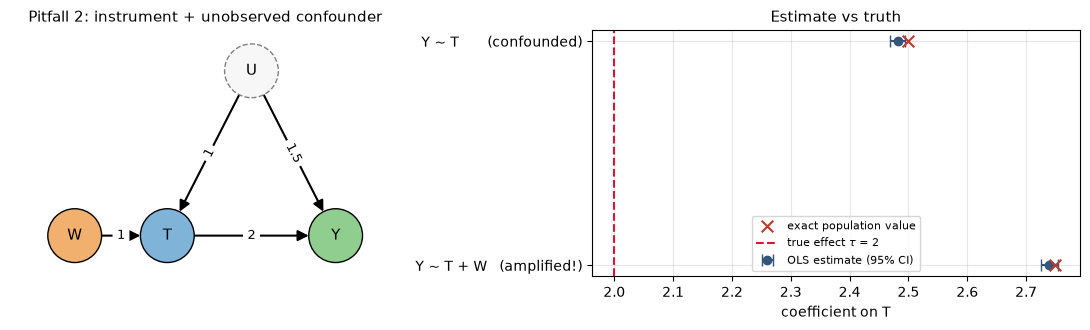

In [17]:
sem_z = [
    ("W", {}, 1.0),
    ("U", {}, 1.0),
    ("T", {"W": 1.0, "U": 1.0}, 1.0),
    ("Y", {"T": TAU, "U": 1.5}, 1.0),
]
df_z, res_z = scenario_report(sem_z, [("Y ~ T       (confounded)", "Y ~ T"),
                                      ("Y ~ T + W   (amplified!)", "Y ~ T + W")])
print(res_z.round(3).to_string())

plot_scenario(sem_z,
              {"W": (-0.9, 0), "T": (0.2, 0), "Y": (2.2, 0), "U": (1.2, 1.1)},
              {"T": "treatment", "Y": "outcome", "W": "control", "U": "unobserved"},
              res_z, "Pitfall 2: instrument + unobserved confounder")

### Pitfall 3 — the Table 2 fallacy

Even a *correct* adjustment set only identifies the effect of the **treatment**. In the
valid regression from scenario (a), `Y ~ T + Z`, the coefficient on the confounder $Z$ is
its *direct* effect (1.5) — not its total causal effect, which includes the path through
$T$: $1.5 + 0.8 \times 2 = 3.1$. Reading every row of a regression table causally is the
"Table 2 fallacy" (Westreich & Greenland 2013). We verify by actually intervening:
push every unit's $Z$ up by 1, regenerate downstream variables, and measure $\Delta Y$.

In [18]:
m_a = smf.ols("Y ~ T + Z", data=df_a).fit()
print(f"coefficient on Z in the (T-valid) regression : {m_a.params['Z']:.3f}")

# do(Z := Z + 1): regenerate T and Y with the SAME structural noises
eps_T = df_a["T"] - 0.8 * df_a["Z"]
eps_Y = df_a["Y"] - TAU * df_a["T"] - 1.5 * df_a["Z"]
Z_new = df_a["Z"] + 1
T_new = 0.8 * Z_new + eps_T
Y_new = TAU * T_new + 1.5 * Z_new + eps_Y
print(f"actual effect of do(Z := Z+1) on Y            : {(Y_new - df_a['Y']).mean():.3f}")
print(f"analytic total effect of Z: 1.5 + 0.8 * 2     = {1.5 + 0.8 * TAU:.1f}")
print("\nA regression valid for T is NOT valid for every coefficient in the table.")

coefficient on Z in the (T-valid) regression : 1.507
actual effect of do(Z := Z+1) on Y            : 3.100
analytic total effect of Z: 1.5 + 0.8 * 2     = 3.1

A regression valid for T is NOT valid for every coefficient in the table.


## 7. Interview corner

**Q1. When does adding a covariate to a regression *hurt* the causal estimate?**
Four structural cases: (1) mediators — you block part of the effect and estimate the direct
effect instead of the total; (2) colliders or descendants of the outcome — you open a
non-causal path and manufacture bias; (3) M-structures — a pre-treatment collider of
unobserved causes, same mechanism; (4) instruments (treatment-only predictors) — under
residual unmeasured confounding they amplify the remaining bias and inflate variance.
Bonus nuance: even a legitimate control can slightly hurt finite-sample precision if it is
weakly related to $Y$ but strongly related to $T$.

**Q2. What is a collider? Give a business example.**
A variable causally downstream of two others: $A \to C \leftarrow B$. Marginally $A$ and $B$
can be independent; *conditioning on $C$* induces association between them (if $C$ tends to
occur when either cause is high, then among cases with $C$, knowing $A$ is low makes $B$
likely high). Business example: among *funded* startups, team quality and market size look
negatively correlated — either can get you funded, so conditioning on funding creates the
trade-off. Product example: among users who contacted support, satisfaction and bug
exposure look negatively related even if independent overall. The analysis error is
filtering or controlling on such a variable ("only look at users who filed a ticket").

**Q3. Why is randomization the gold standard? State it formally.**
Randomization forces $(Y(0), Y(1)) \perp T$. Then $E[Y \mid T=1] - E[Y \mid T=0] =
E[Y(1)] - E[Y(0)] = \text{ATE}$: the selection-bias term
$E[Y(0)\mid T{=}1] - E[Y(0)\mid T{=}0]$ is exactly zero in expectation. Identification
holds *by design* — no functional form, no conditional-ignorability assumption, and balance
extends to unobservables. It also licenses design-based (randomization) inference for
uncertainty. Observational methods must *assume* a version of this independence
conditionally on covariates, which is untestable.

**Q4. ATE vs ATT — when do they differ, and which do common designs target?**
They differ when treatment effects are heterogeneous *and* uptake is correlated with the
effect size (e.g. those who benefit most opt in — our Section 1 world, where ATT > ATE).
An RCT's difference-in-means targets the ATE of the experimental population; matching and
propensity weighting toward the treated target the ATT; an IV targets a LATE for compliers
([04_iv_rdd.ipynb](04_iv_rdd.ipynb)). Senior move: name which estimand the business decision
needs *before* choosing the estimator — "should we expand the program to everyone?" is an
ATE question; "did the program pay for itself on its current users?" is ATT.

**Q5. You ran a clean A/B test but analyzed only users who completed onboarding. Problem?**
Completion is post-treatment: if treatment affects who completes, conditioning on it breaks
the randomization — it's a collider/selection structure (completion is caused by treatment
and by user traits that also drive the outcome). The comparison is now between
non-exchangeable groups. Fix: analyze by assignment (intent-to-treat) on everyone
randomized; if you need the effect among compliers, use the assignment as an instrument.

**Q6. A stakeholder says "just control for everything we log." Your response?**
Adjustment sets come from a causal graph, not from data availability. Logs contain
post-treatment variables (mediators, outcome proxies), colliders, and instruments — each
biases the estimate in a different way (I'd sketch the kitchen-sink demo). Procedure: draw
the DAG with domain experts, choose a set satisfying the backdoor criterion, use remaining
pre-treatment outcome-predictors for precision, and run sensitivity analysis for unobserved
confounding. Also note the seductive failure mode: the kitchen-sink model has the best
$R^2$ and the worst causal estimate.

**Q7. Your DAG is an assumption. How do you defend it?**
Openly: the DAG encodes assumptions, it doesn't discover them. Defenses: (1) it makes
assumptions *explicit and criticizable*, unlike a covariate list; (2) it has testable
implications — implied conditional independencies can be checked in data; (3) robustness:
if several plausible DAGs share a valid adjustment set, the conclusion is insensitive to
the disagreement; (4) sensitivity analysis quantifies how strong an unmeasured confounder
would need to be to overturn the result (E-values, Cinelli-Hazlett robustness values).

## 8. Key takeaways

- Unit-level effects are unobservable; every causal claim is about an average (ATE, ATT,
  CATE). Name your estimand before your estimator.
- Naive comparison $=$ ATT $+$ selection bias — an exact identity. Selection bias lives in
  the assignment mechanism and does not shrink with sample size.
- Randomization makes $(Y(0), Y(1)) \perp T$: zero selection bias by design, balance on
  unobservables, no modeling assumptions.
- All DAGs reduce to forks, chains, and colliders. Conditioning blocks forks and chains but
  **opens** colliders (and their descendants) — conditioning is not a one-way filter.
- Backdoor criterion: adjust for a set of non-descendants of $T$ that blocks every backdoor
  path. "Pre-treatment" is not sufficient (M-bias); "correlated with both $T$ and $Y$" is
  not sufficient either.
- Good controls: confounders (required), pre-treatment outcome predictors (free precision —
  the CUPED idea). Bad controls: mediators (mask), colliders/outcome descendants (fabricate
  bias), instruments (amplify bias under unmeasured confounding).
- Predictive fit is not causal validity: the kitchen-sink model maximizes $R^2$ while
  ruining the estimate.
- Even in a valid model, only the treatment coefficient has the causal interpretation
  (Table 2 fallacy).

## 9. Exercises

**Exercise 1 — OVB arithmetic.** In the SEM $Z \sim N(0,1)$, $T = 0.5 Z + e_T$ with
$\text{Var}(e_T) = 2$, $Y = 2T + 2Z + e_Y$: predict the population value of the naive
`Y ~ T` coefficient with the omitted-variable-bias formula, then verify by simulation and
with `implied_ols`.

**Exercise 2 — descendant of a collider.** Extend scenario (c) with a noisy descendant
$D = 0.8\,C + e_D$. Show that controlling $D$ *also* induces collider bias — attenuated
relative to controlling $C$ itself, but still large. (This is why "we controlled for a
downstream proxy, not the collider itself" is not a defense.)

**Exercise 3 — classify, then verify.** An email campaign $T$ is *targeted* at customers
with high past purchases $P$. Post-email site visits $O$ mediate the effect on next-month
spend $Y$; seasonality $S$ affects only $Y$; and unsubscribing $U$ is driven by receiving
the email and by (dis)satisfaction reflected in $Y$. Classify each of $P, S, O, U$ as
good/bad controls for the *total* effect of $T$ on $Y$, then verify each classification by
regression on simulated data (true total effect: 1.85).

In [19]:
# --- Solution 1 ---
# OVB formula: bias = gamma * Cov(Z,T) / Var(T) = 2 * 0.5 / (0.25 + 2) = 0.4444
sem_ex1 = [("Z", {}, 1.0), ("T", {"Z": 0.5}, np.sqrt(2.0)),
           ("Y", {"T": 2.0, "Z": 2.0}, 1.0)]
bias_pred = 2.0 * 0.5 / (0.5 ** 2 + 2.0)
df_ex1 = simulate_sem(sem_ex1, N, rng)
naive_hat = smf.ols("Y ~ T", data=df_ex1).fit().params["T"]
print(f"OVB formula prediction : tau + 2*0.5/2.25 = {2.0 + bias_pred:.4f}")
print(f"implied_ols population : {implied_ols(sem_ex1, 'Y', ['T'])['T']:.4f}")
print(f"simulated estimate     : {naive_hat:.4f}")

OVB formula prediction : tau + 2*0.5/2.25 = 2.4444
implied_ols population : 2.4444
simulated estimate     : 2.4280


In [20]:
# --- Solution 2 ---
sem_c2 = sem_c + [("D", {"C": 0.8}, 1.0)]
df_c2, res_c2 = scenario_report(
    sem_c2, [("Y ~ T        (correct)", "Y ~ T"),
             ("Y ~ T + C    (collider)", "Y ~ T + C"),
             ("Y ~ T + D    (collider's descendant)", "Y ~ T + D")])
print(res_c2.round(3).to_string())
print("\nControlling the descendant partially conditions on the collider:")
print("bias is attenuated relative to controlling C, but far from zero.")

                                      coef_T   se_T  population_coef  truth  bias (population)
model                                                                                         
Y ~ T        (correct)                 2.006  0.007            2.000    2.0              0.000
Y ~ T + C    (collider)                1.014  0.012            1.013    2.0             -0.987
Y ~ T + D    (collider's descendant)   1.527  0.010            1.518    2.0             -0.482

Controlling the descendant partially conditions on the collider:
bias is attenuated relative to controlling C, but far from zero.


In [21]:
# --- Solution 3 ---
# P: confounder (targets treatment, drives spend)      -> GOOD control (required)
# S: outcome-only predictor                            -> GOOD control (precision)
# O: mediator (T -> O -> Y)                            -> BAD control (masks effect)
# U: collider/descendant of Y (T -> U <- Y)            -> BAD control (induces bias)
n3 = 40_000
P = rng.normal(0, 1, n3)                                  # past purchases (std.)
S = rng.normal(0, 1, n3)                                  # seasonal demand
T = (rng.random(n3) < 1 / (1 + np.exp(-1.0 * P))).astype(float)   # targeted!
O = 0.9 * T + 0.3 * P + rng.normal(0, 1, n3)              # visits (mediator)
Y = 0.5 * T + 1.5 * O + 1.2 * P + 1.0 * S + rng.normal(0, 1, n3)  # spend
U = 0.8 * T - 0.5 * Y + rng.normal(0, 1, n3)              # unsubscribe propensity
email = pd.DataFrame({"P": P, "S": S, "T": T, "O": O, "Y": Y, "U": U})
# total effect = 0.5 (direct) + 0.9 * 1.5 (via visits) = 1.85
res3 = fit_models(email, [
    ("Y ~ T              (confounded by targeting)", "Y ~ T"),
    ("Y ~ T + P          (correct)", "Y ~ T + P"),
    ("Y ~ T + P + S      (correct + precise)", "Y ~ T + P + S"),
    ("Y ~ T + P + O      (mediator: masks)", "Y ~ T + P + O"),
    ("Y ~ T + P + S + U  (collider: fabricates)", "Y ~ T + P + S + U"),
])
res3["truth"] = 1.85
print(res3.round(3).to_string())
print("\nOnly the P (+S) adjustments recover the total effect 1.85;")
print("O returns the direct effect (~0.5); U drags the estimate off in its own direction.")

                                              coef_T   se_T  truth
model                                                             
Y ~ T              (confounded by targeting)   3.201  0.025   1.85
Y ~ T + P          (correct)                   1.860  0.023   1.85
Y ~ T + P + S      (correct + precise)         1.854  0.020   1.85
Y ~ T + P + O      (mediator: masks)           0.520  0.017   1.85
Y ~ T + P + S + U  (collider: fabricates)      1.744  0.015   1.85

Only the P (+S) adjustments recover the total effect 1.85;
O returns the direct effect (~0.5); U drags the estimate off in its own direction.
